## This method does not predict a rating! it learns to rank by assigning a ranking score (dot product between latent user and item)

## How predicitions for know users work:
- (users in the train or test set) 
- get the user id 
- rank all the items for this user - calculate score
- filter the reviewed item_matrix to just the items from test set (or train if evaluating train)
- sort the list of items by the score for that user
- output top k

## For users not in train/test with some review:
- construct the features as before + the identity matrix - concat them
- predict the scores for items as before
- there is not much difference for new user since the method is more heavily item based

## We can calculate similarity using the latent representation of the user that the model is getting



## THE MODEL OUTPUTS SCORE BASED ON THE DOT PRODUCT OF ANY USER-ITEM PAIR IN THE LATENT REPRESENTATION!!! (+ bias :D)
- it the ranks based on this latent score!
- Hence learning is all about learning that trasnform into a space where similarity between user and item facilitates ranking procedure!



## HYbrid because it compares that property of Matrix Factorization with ability to tackle unseen users.
- We may not have ratings between user and item. BUT WE HAVE SIMILARITY IN LATENT SPACE!!!!!
- Therefore we can predict for out of distribution users or items - assum ing same feature formating


# Model Training

In [2]:
import pandas as pd
import numpy as np

In [3]:
ratings_full = pd.read_csv('../data/processed_full/user_item_processed_data.csv')
user_df = pd.read_csv('../data/processed_full/user_features.csv')
item_df = pd.read_csv('../data/processed_full/item_features.csv')

print("Data simulation complete.")
print("\nRatings Full DF shape:", ratings_full.shape)
print("\nItem Features DF shape:", item_df.shape)
print("\nUser Features DF shape:", user_df.shape)
ratings_full.head(5)

Data simulation complete.

Ratings Full DF shape: (1400102, 109)

Item Features DF shape: (27197, 115)

User Features DF shape: (46660, 115)


,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text_emb_0,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,1521,19,1.0,NaN,1.0,NaN,1.0,1.0,NaN,-0.041622,...,0.051783,0.090821,0.023550,-0.028458,0.022709,-0.017830,0.030984,-0.066530,-0.004420,0.022615
1,1524,19,1.0,NaN,NaN,1.0,1.0,NaN,0.6,0.094268,...,0.007869,-0.021458,-0.011069,0.033729,-0.014652,0.031356,0.019260,-0.038565,-0.017441,0.011813
2,1527,19,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.226007,...,0.035656,0.022072,0.031577,-0.085225,-0.019208,0.009750,-0.041887,0.036383,0.069358,0.071002
3,1529,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.026531,...,0.003374,0.041171,0.008375,0.020658,0.000111,-0.012515,-0.019410,-0.014252,0.023997,0.030726
4,1530,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.133377,...,-0.012842,-0.004858,0.077540,-0.057574,0.024631,-0.011781,-0.032293,-0.060140,0.048414,0.012466


In [4]:
item_df.head(5)

,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_ratings,corr_rating_sleep quality,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,19,0.763636,0.843478,0.723810,0.800000,0.806250,0.888889,0.580000,0.046025,0.671665,...,0.014901,0.026970,0.020699,-0.023077,-0.004417,0.010669,0.001858,-0.008007,0.015665,0.010824
1,22,0.832000,0.885714,0.853333,0.800000,0.827273,0.907692,0.783333,0.026151,0.831531,...,-0.003962,0.002048,0.013580,0.005558,-0.015846,0.022196,-0.001296,-0.006309,0.011953,0.003244
2,23,0.805556,0.740000,0.768421,0.826087,0.840000,0.857143,0.827273,0.037657,0.753385,...,-0.010368,0.000376,0.010892,-0.016043,0.011998,0.011799,-0.005985,0.008956,-0.002391,0.008416
3,37,0.770000,0.781818,0.785714,0.690909,0.833333,0.866667,0.850000,0.020921,0.460283,...,0.013826,0.006809,0.005799,-0.017064,-0.003811,0.005202,-0.001809,-0.009861,-0.004628,-0.012835
4,43,0.843478,0.866667,0.800000,0.909091,0.952941,0.927273,0.885714,0.024059,0.288675,...,0.009699,0.010419,0.002312,0.010667,0.009719,-0.003631,-0.013600,0.003903,-0.007008,0.024912


In [5]:
user_df.head(5)

,user_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_rated_items,corr_rating_sleep quality,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,8,0.993750,1.000000,1.000000,1.000000,0.993548,1.000000,0.983333,0.003241,NaN,...,-0.013878,-0.002051,0.011432,-0.004151,-0.002034,-0.019433,-0.007476,-0.004459,0.003242,0.004993
1,12,0.837500,0.800000,0.855556,0.850000,0.922581,0.980000,0.944444,0.003241,0.824589,...,0.007225,-0.004761,0.006946,-0.000852,0.008241,0.000151,0.007699,-0.003459,-0.002650,-0.017329
2,23,0.785185,0.773333,0.777778,0.750000,0.815385,0.846154,0.928571,0.002735,0.837389,...,-0.008082,0.004488,-0.004359,-0.002172,0.020979,-0.011370,0.005325,-0.004700,-0.013979,-0.003620
3,25,0.833333,0.850000,0.830769,0.857143,0.837037,0.855556,0.871429,0.004254,0.382971,...,-0.008281,0.003502,-0.011688,0.002253,0.002044,0.008348,-0.003149,-0.004344,0.007763,0.009010
4,26,0.752381,0.785714,0.722222,0.781818,0.676190,0.737500,0.815385,0.002127,0.836425,...,-0.012055,-0.020730,-0.008691,-0.009486,-0.015362,0.009323,-0.010816,0.002655,-0.000484,-0.002226


In [6]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix, hstack
from lightfm import LightFM
from lightfm.cross_validation import random_train_test_split
from lightfm.evaluation import precision_at_k, auc_score

/Users/maksiuuuuuuu/miniconda3/envs/recsys_env/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [7]:
print("\n--- Step 1: Preprocessing Data ---")

# Handle NaN values in feature dataframes using mean imputation
# For item features
item_feature_cols = item_df.columns[1:] # all columns except item_id
for col in item_feature_cols:
    mean_val = item_df[col].mean()
    item_df[col].fillna(mean_val, inplace=True)

# For user features
user_feature_cols = user_df.columns[1:] # all columns except user_id
for col in user_feature_cols:
    mean_val = user_df[col].mean()
    user_df[col].fillna(mean_val, inplace=True)

print("NaNs in feature dataframes handled.")

# Create User and Item ID Mappings to internal indices
# This is crucial as LightFM needs 0-based consecutive integer indices.
unique_user_ids = sorted(ratings_full['user_id'].unique())
unique_item_ids = sorted(ratings_full['item_id'].unique())

user_id_map = {id: i for i, id in enumerate(unique_user_ids)}
item_id_map = {id: i for i, id in enumerate(unique_item_ids)}

# Create reverse mappings to convert predictions back to original IDs
inv_user_id_map = {i: id for id, i in user_id_map.items()}
inv_item_id_map = {i: id for id, i in item_id_map.items()}

# Apply mapping to the ratings dataframe
ratings_full['user_idx'] = ratings_full['user_id'].map(user_id_map)
ratings_full['item_idx'] = ratings_full['item_id'].map(item_id_map)

print("ID to Index mapping complete.")


--- Step 1: Preprocessing Data ---
NaNs in feature dataframes handled.
ID to Index mapping complete.


/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_21669/2959555610.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  item_df[col].fillna(mean_val, inplace=True)
/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_21669/2959555610.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always b

In [9]:
# --- 1. Weight Calculation & Filtering ---

# Calculate global mean (or you could do user-specific mean)
global_mean = ratings_full['rating'].mean()
print(f"Global rating mean: {global_mean:.2f}")

# Define the threshold for a "Positive" interaction
# We only want to feed the model items the user LIKED.
positive_threshold = 0.8 # its normalized

# Filter the dataframe: Only keep High Ratings (4 and 5)
# This effectively "punishes" low ratings by treating them as unobserved (negative)
positive_ratings = ratings_full[ratings_full['rating'] >= positive_threshold].copy()

# Calculate Weights: Difference from mean (plus a small epsilon to keep weights > 0)
# Example: If mean is 3.5. 
# Rating 5 -> Weight 1.5
# Rating 4 -> Weight 0.5
positive_ratings['weight'] = ((positive_ratings['rating'] - global_mean) + 0.2)*5

# Validating weights are positive (WARP requires positive weights for 'observed' entries)
# If a user rated 4.0 but the mean is 4.2, the weight would be negative. 
# We clip weights to a minimum small value (e.g., 0.1) to ensure the model still sees it as a positive interaction.
positive_ratings['weight'] = positive_ratings['weight'].apply(lambda x: max(x, 0.1))

print(f"Filtered interactions from {len(ratings_full)} to {len(positive_ratings)} positive pairs.")

# --- 2. Create Interaction Matrix ---

# We build the matrix using ONLY the positive ratings.
# The .data attribute of the matrix will hold the 'weights'.
interactions_weighted = coo_matrix(
    (positive_ratings['weight'],
    (positive_ratings['user_idx'], positive_ratings['item_idx'])),
    shape=(len(user_id_map), len(item_id_map))
)

print("Weighted Interaction matrix created.")

# --- 3. Feature Matrix Construction (Standard) ---

# Item Features
item_df_sorted = item_df.set_index('item_id').loc[unique_item_ids]
item_features_meta = csr_matrix(item_df_sorted.values)
item_features_identity = csr_matrix(np.identity(len(item_id_map)))
item_features = hstack([item_features_identity, item_features_meta])

# User Features
user_df_sorted = user_df.set_index('user_id').loc[unique_user_ids]
user_features_meta = csr_matrix(user_df_sorted.values)
user_features_identity = csr_matrix(np.identity(len(user_id_map)))
user_features = hstack([user_features_identity, user_features_meta])

print("\n--- Step 3: Training the LightFM Model ---")

# Split data
# Note: random_train_test_split preserves the data values (weights) in the matrix
train_interactions, test_interactions = random_train_test_split(
    interactions_weighted, 
    test_percentage=0.2, 
    random_state=np.random.RandomState(42)
)

# Instantiate the model
model = LightFM(loss='warp',
                random_state=42,
                learning_rate=0.03, # Slightly higher LR often helps with weighted data
                no_components=32,   # Increased components to capture nuances
                user_alpha=1e-5,
                item_alpha=1e-5
                )

# Train the model
# We pass sample_weight=train_interactions to explicitly tell LightFM to use the matrix values as weights
model.fit(train_interactions,
          user_features=user_features,
          item_features=item_features,
          sample_weight=train_interactions, # <--- IMPORTANT: Pass weights here
          epochs=100,
          num_threads=12,
          verbose=True)

print("\nModel training complete.")

Global rating mean: 0.81
Filtered interactions from 1400102 to 1075627 positive pairs.
Weighted Interaction matrix created.

--- Step 3: Training the LightFM Model ---


Epoch: 100%|██████████| 100/100 [20:52<00:00, 12.52s/it]


Model training complete.


In [10]:
import pickle

# Bundle everything needed for inference
checkpoint = {
    'model': model,
    'user_id_map': user_id_map,       # Map: UserID -> 123
    'item_id_map': item_id_map,       # Map: ItemID -> 456
    'inv_user_id_map': inv_user_id_map, # Map: 123 -> UserID
    'inv_item_id_map': inv_item_id_map, # Map: 456 -> ItemID
    'user_features': user_features,   # The sparse matrix used for training
    'item_features': item_features,   # The sparse matrix used for training
    'item_feature_shape': item_features.shape, # Useful for validation
    'user_feature_shape': user_features.shape,
    'train_interactions': train_interactions,# save the train and test interactions too
    'test_interactions': test_interactions
}

# Save to disk
with open('lightfm_hybrid_model_100e_32d_corrected.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)

print("Model and artifacts saved successfully!")

Model and artifacts saved successfully!


In [7]:
print("\n--- Step 2: Building LightFM Input Matrices ---")

# 1. Interaction Matrix
# We use the ratings as weights. A higher rating means a stronger positive interaction.
interactions = coo_matrix((ratings_full['rating'],
                           (ratings_full['user_idx'], ratings_full['item_idx'])),
                          shape=(len(user_id_map), len(item_id_map)))

print("Interaction matrix created.")

# 2. Item Feature Matrix
# We combine the "identity" of the item with its metadata.
# First, create the metadata features matrix
item_df_sorted = item_df.set_index('item_id').loc[unique_item_ids] # Ensure order matches mapping
item_features_meta = csr_matrix(item_df_sorted.values)

# Then, create the item identity matrix
item_features_identity = csr_matrix(np.identity(len(item_id_map)))

# Combine them horizontally
item_features = hstack([item_features_identity, item_features_meta])

print("Item features matrix created. Shape:", item_features.shape)


# 3. User Feature Matrix
# Similarly, combine user identity with metadata
user_df_sorted = user_df.set_index('user_id').loc[unique_user_ids] # Ensure order
user_features_meta = csr_matrix(user_df_sorted.values)

# User identity matrix
user_features_identity = csr_matrix(np.identity(len(user_id_map)))

# Combine them
user_features = hstack([user_features_identity, user_features_meta])

print("User features matrix created. Shape:", user_features.shape)


--- Step 2: Building LightFM Input Matrices ---
Interaction matrix created.
Item features matrix created. Shape: (27197, 27311)
User features matrix created. Shape: (46660, 46774)


In [8]:
print("\n--- Step 3: Training the LightFM Model ---")

# Split data into training and testing sets
train_interactions, test_interactions = random_train_test_split(
    interactions, test_percentage=0.2, random_state=np.random.RandomState(42)
)

# Instantiate the model
# WARP (Weighted Approximate-Rank Pairwise) is a good loss function for ranking.
model = LightFM(loss='warp',
                random_state=42,
                learning_rate=0.01,
                no_components=16,
                user_alpha=1e-5,    # User regularization
                item_alpha=1e-5     # Item regularization
                ) # Number of latent factors

# Train the model
# We pass the full feature sets, as they are used to represent users/items in both train and test.
model.fit(train_interactions,
          user_features=user_features,
          item_features=item_features,
          epochs=75,
          num_threads=12,
          verbose=True)

print("\nModel training complete.")


--- Step 3: Training the LightFM Model ---


Epoch: 100%|██████████| 75/75 [14:20<00:00, 11.48s/it]


Model training complete.


In [9]:
import pickle

# Bundle everything needed for inference
checkpoint = {
    'model': model,
    'user_id_map': user_id_map,       # Map: UserID -> 123
    'item_id_map': item_id_map,       # Map: ItemID -> 456
    'inv_user_id_map': inv_user_id_map, # Map: 123 -> UserID
    'inv_item_id_map': inv_item_id_map, # Map: 456 -> ItemID
    'user_features': user_features,   # The sparse matrix used for training
    'item_features': item_features,   # The sparse matrix used for training
    'item_feature_shape': item_features.shape, # Useful for validation
    'user_feature_shape': user_features.shape,
    'train_interactions': train_interactions,# save the train and test interactions too
    'test_interactions': test_interactions
}

# Save to disk
with open('lightfm_hybrid_model_75e_16d.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)

print("Model and artifacts saved successfully!")

Model and artifacts saved successfully!


In [10]:
import pickle

# load the model
with open('lightfm_hybrid_model_75e_256d.pkl', 'rb') as f:
    loaded_checkpoint = pickle.load(f)
    
model = loaded_checkpoint['model']
user_id_map = loaded_checkpoint['user_id_map']
item_id_map = loaded_checkpoint['item_id_map']
inv_user_id_map = loaded_checkpoint['inv_user_id_map']
inv_item_id_map = loaded_checkpoint['inv_item_id_map']
user_features = loaded_checkpoint['user_features']
item_features = loaded_checkpoint['item_features']
train_interactions = loaded_checkpoint['train_interactions']
test_interactions = loaded_checkpoint['test_interactions']

In [11]:
import time
from tqdm import tqdm
from collections import defaultdict
import warnings
from scipy.sparse import csr_matrix
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

# Suppress specific LightFM warnings if desired
warnings.filterwarnings('ignore')

k_values = [10, 20, 50, 100]
train_interactions_csr = train_interactions.tocsr()
test_interactions_csr = test_interactions.tocsr()

# Pre-calculate true items for test users (as you did)
true_items_per_user = {
    u: dict(zip(test_interactions_csr[u].indices, test_interactions_csr[u].data))
    for u in range(test_interactions_csr.shape[0]) if test_interactions_csr[u].nnz > 0
}

test_user_indices = list(true_items_per_user.keys())
all_item_indices = np.arange(len(item_id_map))

# --- Accumulators for Metrics ---
ndcg_scores = {k: [] for k in k_values}
hit_counts = {k: 0 for k in k_values}
unique_items_recommended = {k: set() for k in k_values}
recommendation_counts = {k: defaultdict(int) for k in k_values} # For Diversity
total_users_evaluated = 0

In [12]:
from tqdm import tqdm
# --- Batch Processing ---
batch_size = 512 # Higher is faster, but uses more RAM
start_time = time.time()

print(f"Starting evaluation on {len(test_user_indices)} users...")

for start_idx in tqdm(range(0, len(test_user_indices), batch_size)):
    end_idx = start_idx + batch_size
    batch_users = test_user_indices[start_idx:end_idx]
    
    # 1. Predict Batch
    # Reshape logic is correct: repeat users, tile items
    ids_u = np.repeat(batch_users, len(all_item_indices))
    ids_i = np.tile(all_item_indices, len(batch_users))
    
    scores = model.predict(
        ids_u, ids_i, 
        user_features=user_features, 
        item_features=item_features
    )
    
    # Reshape to (n_users_in_batch, n_items)
    batch_scores = scores.reshape(len(batch_users), len(all_item_indices))
    
    # 2. MASK TRAINING ITEMS (Critical Step!)
    # We set scores of items present in training data to -infinity
    for i, user_idx in enumerate(batch_users):
        # Get item indices this user interacted with in TRAIN
        train_items = train_interactions_csr[user_idx].indices
        # Set their score to negative infinity so they are never recommended
        batch_scores[i, train_items] = -np.inf

    # 3. Get Top K indices (Sort once per batch)
    # We only need the top 100 (max k) to calculate all metrics
    max_k = max(k_values)
    
    # argpartition is faster than argsort for top-k, but argsort is safer for exact ranking order
    # stick to argsort for nDCG accuracy
    top_items_indices = np.argsort(-batch_scores, axis=1)[:, :max_k]

    # 4. Calculate Metrics
    for i, user_idx in enumerate(batch_users):
        true_items = true_items_per_user[user_idx]
        recs = top_items_indices[i] # Top 100 items for this user
        
        for k in k_values:
            top_k_recs = recs[:k]
            
            # -- nDCG --
            dcg = 0
            idcg = 0
            
            # DCG
            for rank, item in enumerate(top_k_recs):
                if item in true_items:
                    dcg += true_items[item] / np.log2(rank + 2)
            
            # IDCG (Ideal)
            sorted_true_scores = sorted(true_items.values(), reverse=True)
            for rank, score in enumerate(sorted_true_scores[:k]):
                idcg += score / np.log2(rank + 2)
            
            ndcg_val = (dcg / idcg) if idcg > 0 else 0
            ndcg_scores[k].append(ndcg_val)
            
            # -- Hit Rate --
            # Check if set intersection is not empty
            if not set(top_k_recs).isdisjoint(true_items.keys()):
                hit_counts[k] += 1
            
            # -- Coverage/Diversity Data Collection --
            for item in top_k_recs:
                unique_items_recommended[k].add(item)
                recommendation_counts[k][item] += 1

    total_users_evaluated += len(batch_users)

print(f"\nEvaluation complete in {time.time() - start_time:.2f}s")

Starting evaluation on 45749 users...


100%|██████████| 90/90 [19:07<00:00, 12.75s/it]


Evaluation complete in 1147.06s


In [13]:
# --- Final Calculations ---
ndcg_results = {}
hitrate_results = {}
coverage_results = {}
gini_results = {}

total_catalog_size = len(item_id_map) # Total unique items in your dataset

for k in k_values:
    print(f"\n--- K = {k} ---")
    
    # 1. nDCG
    mean_ndcg = np.mean(ndcg_scores[k])
    ndcg_results[k] = mean_ndcg
    print(f"nDCG: {mean_ndcg:.4f}")
    
    # 2. Hit Rate
    hit_rate = hit_counts[k] / total_users_evaluated
    hitrate_results[k] = hit_rate
    print(f"Hit Rate: {hit_rate:.4f}")
    
    # 3. Catalog Coverage
    # Percentage of items recommended at least once
    cov = len(unique_items_recommended[k]) / total_catalog_size
    coverage_results[k] = cov
    print(f"Coverage: {cov:.4f}")
    
    # 4. Diversity: Gini Coefficient (Inequality)
    # Step A: Create an array representing counts for EVERY item in the catalog
    # (Initialize with zeros so we account for items never recommended)
    all_item_counts = np.zeros(total_catalog_size)
    
    # Step B: Fill in the counts we observed
    for item_idx, count in recommendation_counts[k].items():
        all_item_counts[item_idx] = count
        
    # Step C: Sort counts (Required for Gini formula)
    sorted_counts = np.sort(all_item_counts)
    
    # Step D: Apply Gini Formula
    n = total_catalog_size
    cum_counts = np.cumsum(sorted_counts)
    
    # Standard Gini formula using ordered values:
    # G = (2 * sum(i * x_i) - (n + 1) * sum(x_i)) / (n * sum(x_i))
    # Or the numpy vector way:
    index = np.arange(1, n + 1)
    numerator = np.sum((2 * index - n - 1) * sorted_counts)
    denominator = n * np.sum(sorted_counts)
    
    if denominator == 0:
        gini = 0.0 # If no recommendations were made (edge case)
    else:
        gini = numerator / denominator
        
    gini_results[k] = gini
    print(f"Gini Coefficient: {gini:.4f} (Lower is Better/More Diverse)")


--- K = 10 ---
nDCG: 0.0222
Hit Rate: 0.1189
Coverage: 0.5859
Gini Coefficient: 0.8907 (Lower is Better/More Diverse)

--- K = 20 ---
nDCG: 0.0297
Hit Rate: 0.1879
Coverage: 0.7422
Gini Coefficient: 0.8606 (Lower is Better/More Diverse)

--- K = 50 ---
nDCG: 0.0424
Hit Rate: 0.3138
Coverage: 0.9058
Gini Coefficient: 0.8087 (Lower is Better/More Diverse)

--- K = 100 ---
nDCG: 0.0546
Hit Rate: 0.4362
Coverage: 0.9708
Gini Coefficient: 0.7573 (Lower is Better/More Diverse)


In [14]:
# save the results to a json file
import json
results = {
    'nDCG': ndcg_results,
    'HitRate': hitrate_results,
    'Coverage': coverage_results,
    'Gini': gini_results
}
with open('lightfm_hybrid_model_100e_32d_evaluation_results.json', 'w') as f:
    json.dump(results, f, indent=4)

In [17]:
# # precision and recal for each k in  k_values
# from lightfm.evaluation import precision_at_k, recall_at_k

# precision_values = {}
# recall_values = {}
# for k in k_values:
#     precision = precision_at_k(model, test_interactions, user_features=user_features, item_features=item_features, k=k).mean()
#     recall = recall_at_k(model, test_interactions, user_features=user_features, item_features=item_features, k=k).mean()
#     precision_values[k] = precision
#     recall_values[k] = recall
#     print(f"Precision@{k}: {precision:.4f}, Recall@{k}: {recall:.4f}")

# # Print precision and recall results
# for k in k_values:
#     print(f"Precision@{k}: {precision_values[k]:.4f}")
#     print(f"Recall@{k}: {recall_values[k]:.4f}")

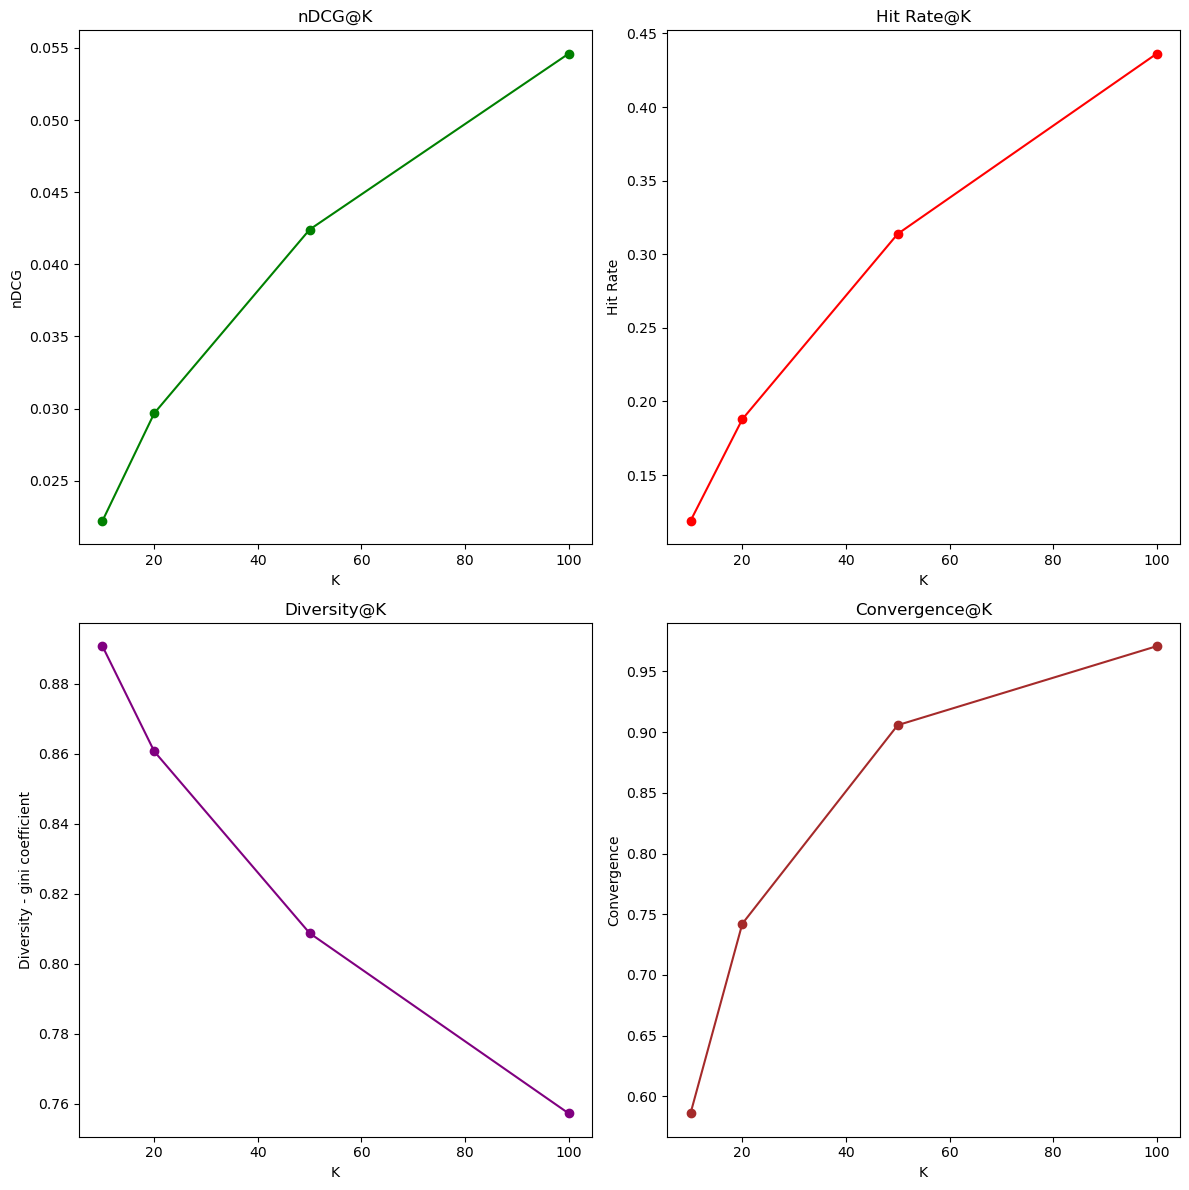

In [15]:
# plot precision_values, recall_values, ndcg_scores , hitrate_values, convergence_values, diveristy_values in subgraphs for k
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
axs[0, 0].plot(k_values, [ndcg_results[k] for k in k_values], marker='o', color='green')
axs[0, 0].set_title('nDCG@K')
axs[0, 0].set_xlabel('K')
axs[0, 0].set_ylabel('nDCG')
axs[0, 1].plot(k_values, [hitrate_results[k] for k in k_values], marker='o', color='red')  
axs[0, 1].set_title('Hit Rate@K')
axs[0, 1].set_xlabel('K')
axs[0, 1].set_ylabel('Hit Rate')
axs[1, 0].plot(k_values, [gini_results[k] for k in k_values], marker='o', color='purple')
axs[1, 0].set_title('Diversity@K')
axs[1, 0].set_xlabel('K')
axs[1, 0].set_ylabel('Diversity - gini coefficient')
axs[1, 1].plot(k_values, [coverage_results[k] for k in k_values], marker='o', color='brown')
axs[1, 1].set_title('Convergence@K')
axs[1, 1].set_xlabel('K')
axs[1, 1].set_ylabel('Convergence')
plt.tight_layout()
plt.show()

Important Stuff:
1. mask to avoid leaking training items in eval: recommend only non rated items
2. Warp not rarting prediction - binary rating: better ratting has to be ranked higher - contrastive approach


# Eval

Loading model and artifacts...
Model loaded. Evaluating on 46455 test users.
Total Items: 27197
Pre-computing representations...
Starting evaluation on 46455 users with 93 batches...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    1.4s
[Parallel(n_jobs=-1)]: Done  89 out of  93 | elapsed:    2.1s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  93 out of  93 | elapsed:    2.2s finished


Calculations completed in 2.33s
Aggregating results...

--- Final Results ---
{
    "nDCG": {
        "10": 0.01571296297097641,
        "20": 0.021046211822738657,
        "50": 0.03146238159259515,
        "100": 0.04215194874242638
    },
    "HitRate": {
        "10": 0.09955871273275213,
        "20": 0.1620492950166828,
        "50": 0.2884296631148423,
        "100": 0.41319556560111936
    },
    "Precision": {
        "10": 0.01084705629103433,
        "20": 0.009341298030351938,
        "50": 0.007436013346249061,
        "100": 0.00603142826391129
    },
    "Coverage": {
        "10": 0.08526675736294444,
        "20": 0.12497701952421222,
        "50": 0.21046438945471926,
        "100": 0.307386844137221
    },
    "Gini": {
        "10": 0.9867893294070897,
        "20": 0.9798188306451949,
        "50": 0.964599565248478,
        "100": 0.9456140610961467
    }
}


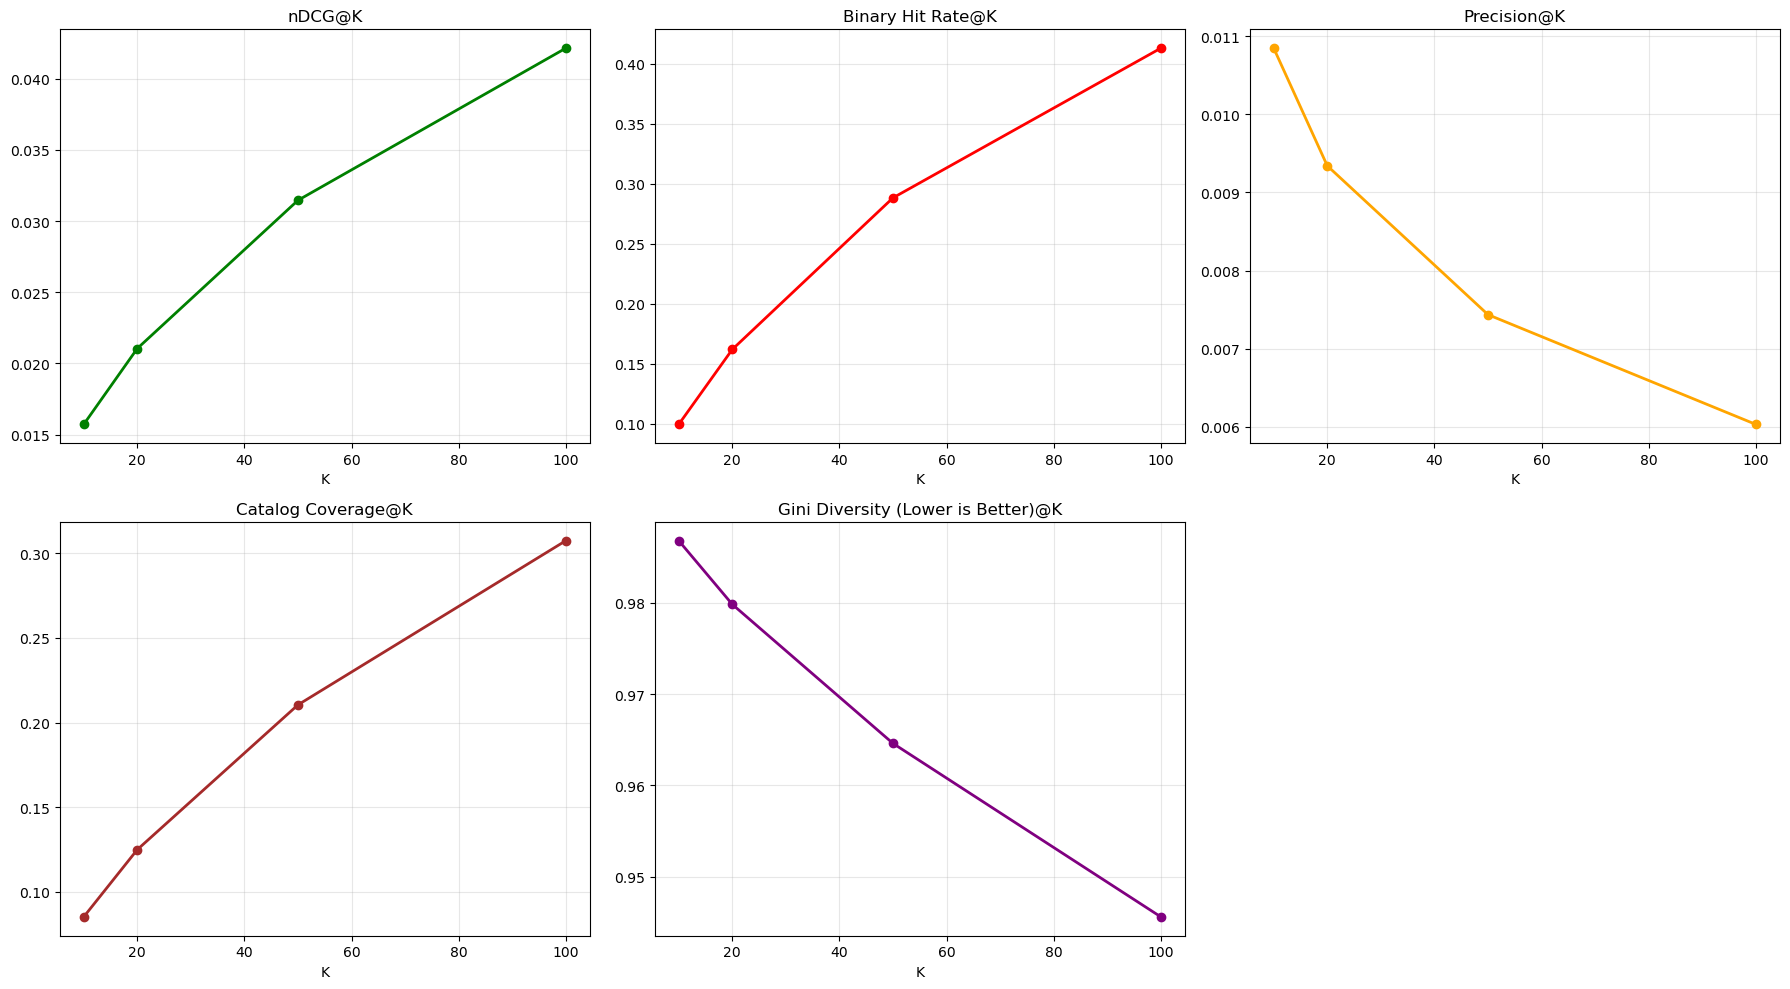

In [10]:
import pandas as pd
import numpy as np
import pickle
import time
import json
import warnings
import gc
from scipy.sparse import csr_matrix
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

# Suppress warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. LOAD MODEL
# ----------------------------------------------------------------------------
print("Loading model and artifacts...")
with open('lightfm_hybrid_model_75e_16d.pkl', 'rb') as f:
    checkpoint = pickle.load(f)

model = checkpoint['model']
item_id_map = checkpoint['item_id_map']
user_features = checkpoint['user_features']
item_features = checkpoint['item_features']
train_interactions = checkpoint['train_interactions']
test_interactions = checkpoint['test_interactions']

# Convert to CSR for fast slicing and explicitly cast to float32 for memory efficiency
train_csr = train_interactions.tocsr().astype(np.float32)
test_csr = test_interactions.tocsr().astype(np.float32)

# Identify valid test users
test_user_indices = np.array([u for u in range(test_csr.shape[0]) if test_csr[u].getnnz() > 0])

print(f"Model loaded. Evaluating on {len(test_user_indices)} test users.")
print(f"Total Items: {len(item_id_map)}")

# ----------------------------------------------------------------------------
# 2. PRE-COMPUTE EMBEDDINGS (float32)
# ----------------------------------------------------------------------------
print("Pre-computing representations...")

# Extract representations
user_biases, user_embeddings = model.get_user_representations(features=user_features)
item_biases, item_embeddings = model.get_item_representations(features=item_features)

# Enforce float32 to ensure Mac 'Accelerate' BLAS works fastest and saves RAM
user_biases = user_biases.astype(np.float32)
user_embeddings = user_embeddings.astype(np.float32)
item_biases = item_biases.astype(np.float32)
item_embeddings = item_embeddings.astype(np.float32)

# Slice only test users
test_user_biases = user_biases[test_user_indices]
test_user_embeddings = user_embeddings[test_user_indices]

# Free up memory (optional, good practice in notebooks)
del user_features, item_features, checkpoint
gc.collect()

# ----------------------------------------------------------------------------
# 3. VERIFIED BATCH PROCESSOR
# ----------------------------------------------------------------------------
def process_batch(batch_indices, 
                  batch_u_biases, batch_u_embs, 
                  all_i_biases, all_i_embs,
                  train_csr_sub, test_csr_sub, 
                  k_list):
    """
    Calculates metrics for a batch of users.
    """
    # 1. Score Calculation (Vectorized)
    # Result Shape: (Batch_Size, n_items)
    # Using float32 for speed
    batch_scores = (batch_u_biases[:, None] + all_i_biases) + \
                   (batch_u_embs @ all_i_embs.T)

    # 2. Mask Training Items
    # We set training items to -infinity so they appear last in sorting
    for row_i in range(len(batch_indices)):
        # We passed a sliced CSR, so row_i corresponds correctly to the batch
        seen_indices = train_csr_sub[row_i].indices
        batch_scores[row_i, seen_indices] = -np.inf

    # 3. Get Top K Indices
    max_k = max(k_list)
    
    # argpartition finds the k largest elements (smallest negatives) efficiently O(N)
    # We partition around the k-th element. The top K are roughly in the first max_k positions.
    top_k_unsorted_arg = np.argpartition(-batch_scores, max_k, axis=1)[:, :max_k]
    
    # We must sort these top K to get exact ranking for nDCG
    top_k_sorted = np.zeros(top_k_unsorted_arg.shape, dtype=int)
    
    for i in range(len(batch_indices)):
        indices = top_k_unsorted_arg[i]
        scores = batch_scores[i, indices]
        # sort descending
        sort_order = np.argsort(-scores)
        top_k_sorted[i] = indices[sort_order]

    # 4. Metrics
    batch_metrics = {
        'ndcg': {k: 0.0 for k in k_list},
        'hit': {k: 0 for k in k_list},
        'precision': {k: 0.0 for k in k_list},
        'rec_counts': {k: {} for k in k_list},
        'count': len(batch_indices)
    }

    # Iterate through users in this batch
    for i in range(len(batch_indices)):
        # Ground Truth
        true_indices = test_csr_sub[i].indices
        true_values = test_csr_sub[i].data
        true_items_set = set(true_indices)
        true_ratings_map = dict(zip(true_indices, true_values))
        
        # Predictions
        recs = top_k_sorted[i]
        
        for k in k_list:
            top_k_recs = recs[:k]
            
            # --- Hit Rate (Binary) & Precision ---
            hits = 0
            for item in top_k_recs:
                if item in true_items_set:
                    hits += 1
            
            if hits > 0:
                batch_metrics['hit'][k] += 1
            
            batch_metrics['precision'][k] += (hits / k)

            # --- nDCG ---
            dcg = 0.0
            idcg = 0.0
            
            # DCG Calculation
            for rank, item in enumerate(top_k_recs):
                if item in true_items_set:
                    rel = true_ratings_map.get(item, 1.0) # Default to 1.0 if implicit
                    dcg += rel / np.log2(rank + 2)
            
            # IDCG Calculation
            # Sort true values descending to find ideal order
            sorted_true_vals = sorted(true_values, reverse=True)
            # We can only achieve IDCG for min(num_true_items, k)
            limit = min(len(sorted_true_vals), k)
            
            for rank in range(limit):
                idcg += sorted_true_vals[rank] / np.log2(rank + 2)
                
            if idcg > 0:
                batch_metrics['ndcg'][k] += (dcg / idcg)

            # --- Diversity Counting ---
            for item in top_k_recs:
                batch_metrics['rec_counts'][k][item] = batch_metrics['rec_counts'][k].get(item, 0) + 1

    return batch_metrics

# ----------------------------------------------------------------------------
# 4. PARALLEL EXECUTION SETUP
# ----------------------------------------------------------------------------
k_values = [10, 20, 50, 100]
n_test_users = len(test_user_indices)

# Optimization:
# To avoid pickling the MASSIVE full CSR matrix to every worker (slow on Mac 'spawn'),
# we slice the CSR matrix *before* sending it to the worker.
# This makes the pickling overhead much smaller.

batch_size = 500 # Safe for 16GB RAM. If you have 8GB, try 250.
n_jobs = -1 

batches = []
for start in range(0, n_test_users, batch_size):
    end = min(start + batch_size, n_test_users)
    
    # The indices in the test_user_indices array
    batch_idx_range = range(start, end)
    
    # The actual User IDs (indices in the full matrix)
    original_uids = test_user_indices[start:end]
    
    # PRE-SLICE DATA: Crucial for Mac Performance
    # We only send the small slice of the sparse matrix relevant to this batch
    train_sub = train_csr[original_uids]
    test_sub = test_csr[original_uids]
    
    batches.append((
        batch_idx_range,
        original_uids,
        train_sub,
        test_sub
    ))

print(f"Starting evaluation on {n_test_users} users with {len(batches)} batches...")
start_time = time.time()

# Execute
results = Parallel(n_jobs=n_jobs, verbose=5)(
    delayed(process_batch)(
        batch_idx,
        test_user_biases[batch_idx],     # Slice embeddings
        test_user_embeddings[batch_idx], # Slice embeddings
        item_biases,
        item_embeddings,
        train_sub, # Pre-sliced sparse matrix
        test_sub,  # Pre-sliced sparse matrix
        k_values
    ) for batch_idx, original_uids, train_sub, test_sub in batches
)

print(f"Calculations completed in {time.time() - start_time:.2f}s")

# ----------------------------------------------------------------------------
# 5. AGGREGATE METRICS
# ----------------------------------------------------------------------------
print("Aggregating results...")
final_metrics = {
    'nDCG': {}, 'HitRate': {}, 'Precision': {}, 'Coverage': {}, 'Gini': {}
}

total_users = n_test_users
total_items = len(item_id_map)

# Combine results
global_counts = {k: {} for k in k_values}

for k in k_values:
    sum_ndcg = 0.0
    sum_hit = 0
    sum_precision = 0.0
    
    for res in results:
        sum_ndcg += res['ndcg'][k]
        sum_hit += res['hit'][k]
        sum_precision += res['precision'][k]
        
        for item, cnt in res['rec_counts'][k].items():
            global_counts[k][item] = global_counts[k].get(item, 0) + cnt
            
    # Averaging
    final_metrics['nDCG'][k] = sum_ndcg / total_users
    final_metrics['HitRate'][k] = sum_hit / total_users
    final_metrics['Precision'][k] = sum_precision / total_users
    
    # Coverage
    unique_items = len(global_counts[k])
    final_metrics['Coverage'][k] = unique_items / total_items
    
    # Gini Coefficient
    # 1. Expand counts to full catalog size (fill zeros)
    # Using numpy for speed
    counts_array = np.zeros(total_items, dtype=np.float32)
    
    # Extract keys/values safely
    if global_counts[k]:
        idx = np.array(list(global_counts[k].keys()))
        vals = np.array(list(global_counts[k].values()))
        counts_array[idx] = vals
        
    # 2. Sort
    sorted_counts = np.sort(counts_array)
    
    # 3. Gini Formula
    n = total_items
    cumulative_sum = np.cumsum(sorted_counts)
    sum_vals = cumulative_sum[-1]
    
    if sum_vals == 0:
        final_metrics['Gini'][k] = 0.0
    else:
        # Standard Gini calculation vectorized
        index = np.arange(1, n + 1)
        numerator = np.sum((2 * index - n - 1) * sorted_counts)
        denominator = n * sum_vals
        final_metrics['Gini'][k] = numerator / denominator

# ----------------------------------------------------------------------------
# 6. OUTPUT
# ----------------------------------------------------------------------------
print("\n--- Final Results ---")
print(json.dumps(final_metrics, indent=4))

# Plotting
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
metrics_to_plot = [
    ('nDCG', 'nDCG', 'green'),
    ('HitRate', 'Binary Hit Rate', 'red'),
    ('Precision', 'Precision', 'orange'),
    ('Coverage', 'Catalog Coverage', 'brown'),
    ('Gini', 'Gini Diversity (Lower is Better)', 'purple')
]

# Map metrics to subplots
plot_positions = [(0,0), (0,1), (0,2), (1,0), (1,1)]

for (key, title, color), (row, col) in zip(metrics_to_plot, plot_positions):
    y_vals = [final_metrics[key][k] for k in k_values]
    axs[row, col].plot(k_values, y_vals, marker='o', color=color, linewidth=2)
    axs[row, col].set_title(f'{title}@K')
    axs[row, col].set_xlabel('K')
    axs[row, col].grid(True, alpha=0.3)

axs[1, 2].axis('off') # Hide empty plot
plt.tight_layout()
plt.show()

Loading model and artifacts...
Model loaded. Evaluating on 46455 test users.
Pre-computing representations...
Starting evaluation on 46455 users...
Processing first batch (Debug Mode)...

--- DEBUG: User Index 0 ---
Total True Test Items: 6
True Items (First 10): [3336, 350147, 358435, 361334, 363620, 364685]
True Ratings (First 10): [1. 1. 1. 1. 1. 1.]
Top 10 Recommendations: [362443, 50763, 51082, 361960, 362991, 361580, 362583, 364662, 51137, 50803]
Overlap (Any Rating) in Top 100: 0 items
------------------------------------------

Processing remaining batches in parallel...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    1.0s
[Parallel(n_jobs=-1)]: Done  88 out of  92 | elapsed:    1.8s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  92 out of  92 | elapsed:    1.8s finished


Done in 2.10s

--- Final Results ---
{
    "nDCG": {
        "10": 0.01571296297097641,
        "20": 0.021046211822738657,
        "50": 0.03146238159259515,
        "100": 0.04215194874242638
    },
    "HitRate_Any": {
        "10": 0.09955871273275213,
        "20": 0.1620492950166828,
        "50": 0.2884296631148423,
        "100": 0.41319556560111936
    },
    "HitRate_Strict": {
        "10": 0.0,
        "20": 0.0,
        "50": 0.0,
        "100": 0.0
    },
    "Precision_Any": {
        "10": 0.01084705629103433,
        "20": 0.009341298030351938,
        "50": 0.007436013346249061,
        "100": 0.00603142826391129
    },
    "Precision_Strict": {
        "10": 0.0,
        "20": 0.0,
        "50": 0.0,
        "100": 0.0
    },
    "Coverage": {
        "10": 0.08526675736294444,
        "20": 0.12497701952421222,
        "50": 0.21046438945471926,
        "100": 0.307386844137221
    },
    "Gini": {
        "10": 0.9867893294070897,
        "20": 0.9798188306451949,


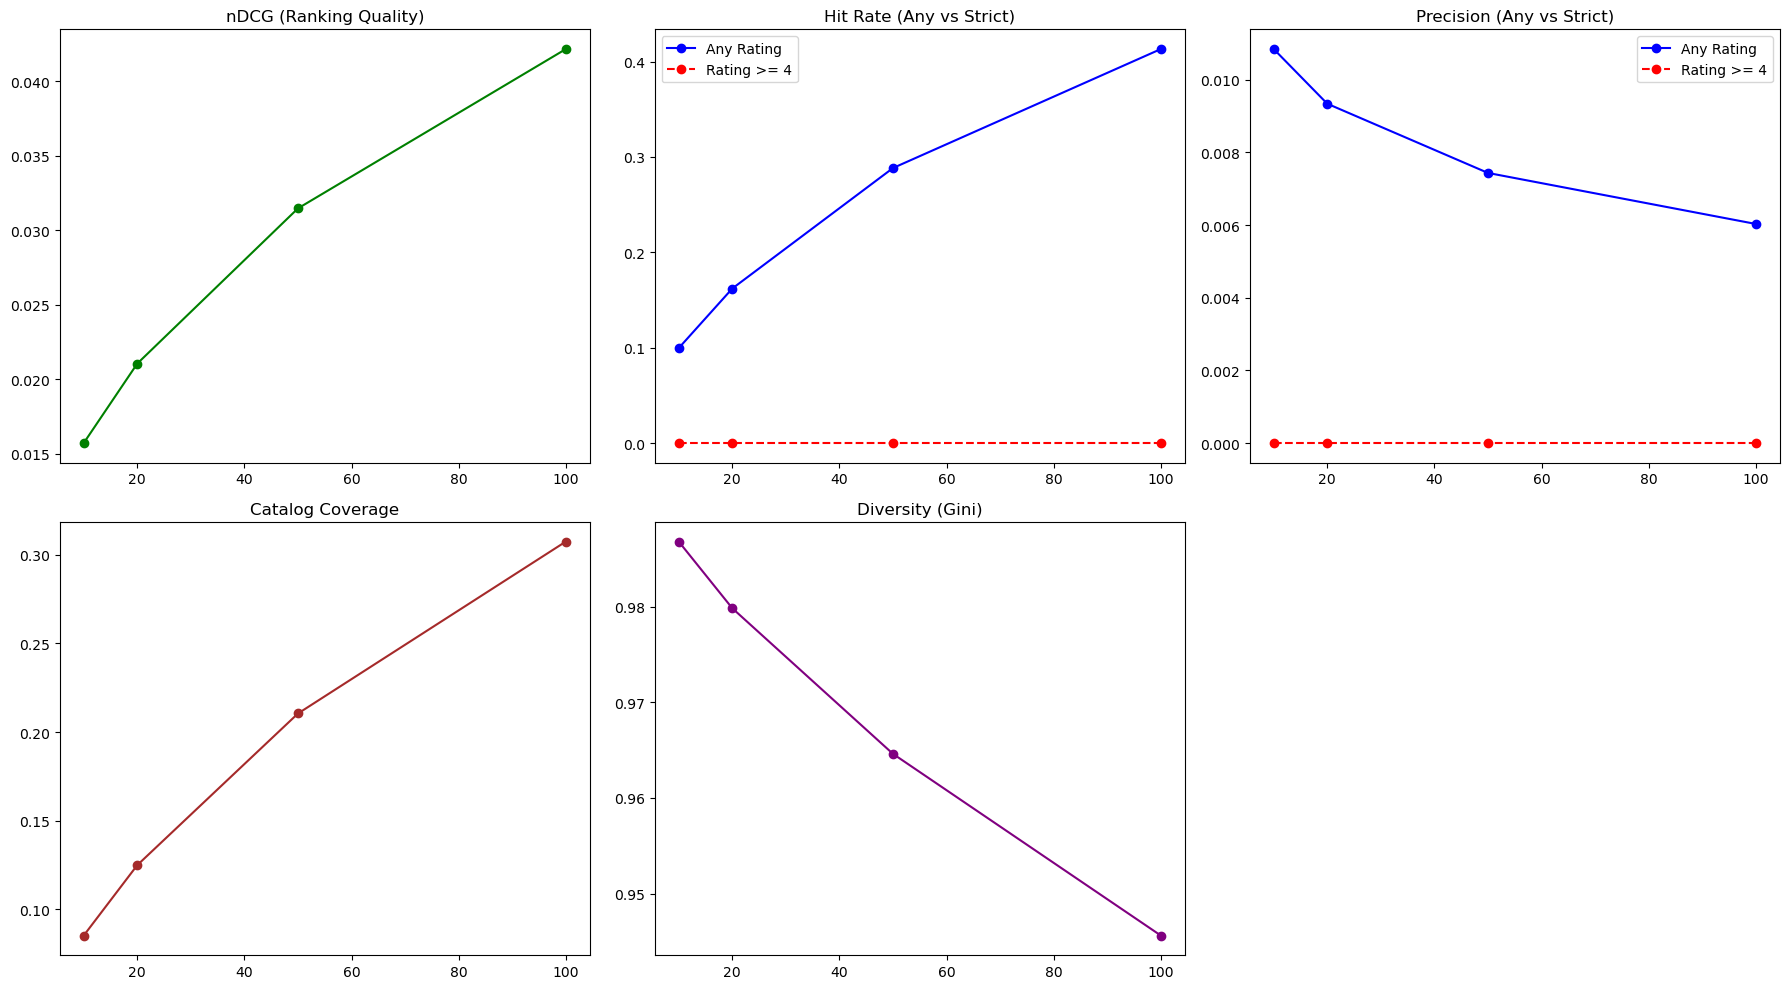

In [13]:
import pandas as pd
import numpy as np
import pickle
import time
import json
import warnings
import gc
from scipy.sparse import csr_matrix
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

# Suppress warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. LOAD MODEL
# ----------------------------------------------------------------------------
print("Loading model and artifacts...")
with open('lightfm_hybrid_model_75e_16d.pkl', 'rb') as f:
    checkpoint = pickle.load(f)

model = checkpoint['model']
item_id_map = checkpoint['item_id_map']
inv_item_id_map = checkpoint['inv_item_id_map'] # Needed for debug printing
user_features = checkpoint['user_features']
item_features = checkpoint['item_features']
train_interactions = checkpoint['train_interactions']
test_interactions = checkpoint['test_interactions']

# Convert to CSR and float32
train_csr = train_interactions.tocsr().astype(np.float32)
test_csr = test_interactions.tocsr().astype(np.float32)

# Filter: Only evaluate users who actually exist in the test set
test_user_indices = np.array([u for u in range(test_csr.shape[0]) if test_csr[u].getnnz() > 0])

print(f"Model loaded. Evaluating on {len(test_user_indices)} test users.")

# ----------------------------------------------------------------------------
# 2. PRE-COMPUTE EMBEDDINGS
# ----------------------------------------------------------------------------
print("Pre-computing representations...")
user_biases, user_embeddings = model.get_user_representations(features=user_features)
item_biases, item_embeddings = model.get_item_representations(features=item_features)

# Cast to float32
user_biases = user_biases.astype(np.float32)
user_embeddings = user_embeddings.astype(np.float32)
item_biases = item_biases.astype(np.float32)
item_embeddings = item_embeddings.astype(np.float32)

# Slice only test users
test_user_biases = user_biases[test_user_indices]
test_user_embeddings = user_embeddings[test_user_indices]

del user_features, item_features, checkpoint
gc.collect()

# ----------------------------------------------------------------------------
# 3. WORKER FUNCTION WITH DUAL METRICS
# ----------------------------------------------------------------------------
def process_batch(batch_indices, 
                  batch_u_biases, batch_u_embs, 
                  all_i_biases, all_i_embs,
                  train_csr_sub, test_csr_sub, 
                  k_list,
                  debug_mode=False, inv_item_map=None):
    
    # 1. Prediction (Score = U * I)
    batch_scores = (batch_u_biases[:, None] + all_i_biases) + \
                   (batch_u_embs @ all_i_embs.T)

    # 2. Mask Training Items (Set to -inf)
    for row_i in range(len(batch_indices)):
        seen_indices = train_csr_sub[row_i].indices
        batch_scores[row_i, seen_indices] = -np.inf

    # 3. Sort Top K
    max_k = max(k_list)
    top_k_unsorted_arg = np.argpartition(-batch_scores, max_k, axis=1)[:, :max_k]
    top_k_sorted = np.zeros(top_k_unsorted_arg.shape, dtype=int)
    
    for i in range(len(batch_indices)):
        indices = top_k_unsorted_arg[i]
        scores = batch_scores[i, indices]
        top_k_sorted[i] = indices[np.argsort(-scores)]

    # 4. Calculate Metrics
    batch_metrics = {
        'ndcg': {k: 0.0 for k in k_list},
        'hit_strict': {k: 0 for k in k_list}, # Rated >= 4.0
        'hit_any': {k: 0 for k in k_list},    # Rated anything
        'precision_strict': {k: 0.0 for k in k_list},
        'precision_any': {k: 0.0 for k in k_list},
        'rec_counts': {k: {} for k in k_list},
        'count': len(batch_indices)
    }

    for i in range(len(batch_indices)):
        # --- Ground Truth ---
        # These are the items hidden in the test set for this user
        true_indices = test_csr_sub[i].indices
        true_ratings = test_csr_sub[i].data
        true_map = dict(zip(true_indices, true_ratings))
        
        # Define "Positive" sets
        # 1. Any Interaction (Did they watch it?)
        any_items_set = set(true_indices)
        
        # 2. Strict Interaction (Did they LIKE it? >= 4.0)
        mask_strict = true_ratings >= 4.0
        strict_items_set = set(true_indices[mask_strict])
        
        # Predictions
        recs = top_k_sorted[i]

        # --- DEBUG PRINT FOR FIRST USER IN FIRST BATCH ---
        if debug_mode and i == 0:
            print(f"\n--- DEBUG: User Index {batch_indices[0]} ---")
            print(f"Total True Test Items: {len(true_indices)}")
            print(f"True Items (First 10): { [inv_item_map.get(x, x) for x in true_indices[:10]] }")
            print(f"True Ratings (First 10): {true_ratings[:10]}")
            print(f"Top 10 Recommendations: { [inv_item_map.get(x, x) for x in recs[:10]] }")
            
            # Check overlap manually
            overlap = set(recs[:max_k]).intersection(any_items_set)
            print(f"Overlap (Any Rating) in Top {max_k}: {len(overlap)} items")
            if len(overlap) > 0:
                print(f"Found items: {[inv_item_map.get(x,x) for x in overlap]}")
            print("------------------------------------------\n")

        for k in k_list:
            top_k_recs = recs[:k]
            
            # --- 1. Hit Rate & Precision (Any Rating) ---
            hits_any = 0
            for item in top_k_recs:
                if item in any_items_set:
                    hits_any += 1
            
            if hits_any > 0:
                batch_metrics['hit_any'][k] += 1
            batch_metrics['precision_any'][k] += (hits_any / k)

            # --- 2. Hit Rate & Precision (Strict >= 4.0) ---
            hits_strict = 0
            for item in top_k_recs:
                if item in strict_items_set:
                    hits_strict += 1
            
            if hits_strict > 0:
                batch_metrics['hit_strict'][k] += 1
            batch_metrics['precision_strict'][k] += (hits_strict / k)

            # --- 3. nDCG (Using Actual Ratings) ---
            # We want high rated items at the top. 
            dcg = 0.0
            idcg = 0.0
            
            for rank, item in enumerate(top_k_recs):
                if item in true_map:
                    # Give credit based on the actual rating (1.0 to 5.0)
                    dcg += true_map[item] / np.log2(rank + 2)
            
            # Ideal Order: Sort the user's ACTUAL ratings descending
            sorted_true_vals = sorted(true_ratings, reverse=True)
            limit = min(len(sorted_true_vals), k)
            for rank in range(limit):
                idcg += sorted_true_vals[rank] / np.log2(rank + 2)
                
            if idcg > 0:
                batch_metrics['ndcg'][k] += (dcg / idcg)

            # --- 4. Diversity ---
            for item in top_k_recs:
                batch_metrics['rec_counts'][k][item] = batch_metrics['rec_counts'][k].get(item, 0) + 1

    return batch_metrics

# ----------------------------------------------------------------------------
# 4. EXECUTE
# ----------------------------------------------------------------------------
k_values = [10, 20, 50, 100]
n_test_users = len(test_user_indices)
batch_size = 500
n_jobs = -1 

batches = []
for start in range(0, n_test_users, batch_size):
    end = min(start + batch_size, n_test_users)
    batches.append((
        range(start, end),
        test_user_indices[start:end],
        train_csr[test_user_indices[start:end]],
        test_csr[test_user_indices[start:end]]
    ))

print(f"Starting evaluation on {n_test_users} users...")
start_time = time.time()

# We run the first batch separately (single thread) to get the DEBUG print
# Then we run the rest in parallel
first_batch = batches[0]
remaining_batches = batches[1:]

results = []

# Process first batch with DEBUG=True
print("Processing first batch (Debug Mode)...")
res_first = process_batch(
    first_batch[0],
    test_user_biases[first_batch[0]],
    test_user_embeddings[first_batch[0]],
    item_biases, item_embeddings,
    first_batch[2], first_batch[3],
    k_values,
    debug_mode=True, inv_item_map=inv_item_id_map
)
results.append(res_first)

# Process rest in parallel
if remaining_batches:
    print("Processing remaining batches in parallel...")
    res_rest = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(process_batch)(
            b_idx,
            test_user_biases[b_idx],
            test_user_embeddings[b_idx],
            item_biases, item_embeddings,
            train_sub, test_sub,
            k_values
        ) for b_idx, u_idx, train_sub, test_sub in remaining_batches
    )
    results.extend(res_rest)

print(f"Done in {time.time() - start_time:.2f}s")

# ----------------------------------------------------------------------------
# 5. AGGREGATE
# ----------------------------------------------------------------------------
final_metrics = {
    'nDCG': {}, 'HitRate_Any': {}, 'HitRate_Strict': {}, 
    'Precision_Any': {}, 'Precision_Strict': {}, 
    'Coverage': {}, 'Gini': {}
}

total_users = n_test_users
total_items = len(item_id_map)
global_counts = {k: {} for k in k_values}

for k in k_values:
    # Accumulators
    acc = {key: 0.0 for key in ['ndcg', 'hit_strict', 'hit_any', 'precision_strict', 'precision_any']}
    
    for res in results:
        for key in acc:
            acc[key] += res[key][k]
        
        for item, cnt in res['rec_counts'][k].items():
            global_counts[k][item] = global_counts[k].get(item, 0) + cnt
    
    # Averages
    final_metrics['nDCG'][k] = acc['ndcg'] / total_users
    final_metrics['HitRate_Any'][k] = acc['hit_any'] / total_users
    final_metrics['HitRate_Strict'][k] = acc['hit_strict'] / total_users
    final_metrics['Precision_Any'][k] = acc['precision_any'] / total_users
    final_metrics['Precision_Strict'][k] = acc['precision_strict'] / total_users
    
    # Coverage & Gini
    unique = len(global_counts[k])
    final_metrics['Coverage'][k] = unique / total_items
    
    # Gini
    counts_array = np.zeros(total_items, dtype=np.float32)
    if global_counts[k]:
        counts_array[np.array(list(global_counts[k].keys()))] = np.array(list(global_counts[k].values()))
    sorted_counts = np.sort(counts_array)
    n = total_items
    sum_vals = np.sum(sorted_counts)
    if sum_vals == 0:
        final_metrics['Gini'][k] = 0.0
    else:
        index = np.arange(1, n + 1)
        numerator = np.sum((2 * index - n - 1) * sorted_counts)
        denominator = n * sum_vals
        final_metrics['Gini'][k] = numerator / denominator

# ----------------------------------------------------------------------------
# 6. OUTPUT
# ----------------------------------------------------------------------------
print("\n--- Final Results ---")
print(json.dumps(final_metrics, indent=4))

# PLOT
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# 1. nDCG
axs[0, 0].plot(k_values, [final_metrics['nDCG'][k] for k in k_values], 'g-o')
axs[0, 0].set_title('nDCG (Ranking Quality)')

# 2. Hit Rates (Comparison)
axs[0, 1].plot(k_values, [final_metrics['HitRate_Any'][k] for k in k_values], 'b-o', label='Any Rating')
axs[0, 1].plot(k_values, [final_metrics['HitRate_Strict'][k] for k in k_values], 'r--o', label='Rating >= 4')
axs[0, 1].set_title('Hit Rate (Any vs Strict)')
axs[0, 1].legend()

# 3. Precision (Comparison)
axs[0, 2].plot(k_values, [final_metrics['Precision_Any'][k] for k in k_values], 'b-o', label='Any Rating')
axs[0, 2].plot(k_values, [final_metrics['Precision_Strict'][k] for k in k_values], 'r--o', label='Rating >= 4')
axs[0, 2].set_title('Precision (Any vs Strict)')
axs[0, 2].legend()

# 4. Coverage
axs[1, 0].plot(k_values, [final_metrics['Coverage'][k] for k in k_values], 'brown', marker='o')
axs[1, 0].set_title('Catalog Coverage')

# 5. Gini
axs[1, 1].plot(k_values, [final_metrics['Gini'][k] for k in k_values], 'purple', marker='o')
axs[1, 1].set_title('Diversity (Gini)')

axs[1, 2].axis('off')
plt.tight_layout()
plt.show()

Loading model and artifacts...
Model loaded. Evaluating on 46455 test users.
Pre-computing representations...
Starting evaluation on 46455 users...
Running debug batch...

--- DEBUG USER 0 ---
User Train Mean Rating: 0.99
Test Items (Total): 6
Test Items (Positive >= 0.99): 6
Top 10 Recs: [362443, 50763, 51082, 361960, 362991, 361580, 362583, 364662, 51137, 50803]
Hits found in Top 100: 0
------------------------------------

Running 92 batches in parallel...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    1.1s
[Parallel(n_jobs=-1)]: Done  88 out of  92 | elapsed:    1.8s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  92 out of  92 | elapsed:    1.9s finished


Calculations completed in 2.15s
Aggregating results...

--- Final Personalized Evaluation Results ---
{
    "nDCG": {
        "10": 0.01571296297097641,
        "20": 0.021046211822738657,
        "50": 0.03146238159259515,
        "100": 0.04215194874242638
    },
    "HitRate": {
        "10": 0.06257668711656442,
        "20": 0.102486277042299,
        "50": 0.18667527714993004,
        "100": 0.27620277688085243
    },
    "Precision": {
        "10": 0.006636529975244858,
        "20": 0.005644171779141103,
        "50": 0.004458077709611454,
        "100": 0.003593369927887204
    },
    "Coverage": {
        "10": 0.08526675736294444,
        "20": 0.12497701952421222,
        "50": 0.21046438945471926,
        "100": 0.307386844137221
    },
    "Gini": {
        "10": 0.9867893294070897,
        "20": 0.9798188306451949,
        "50": 0.964599565248478,
        "100": 0.9456140610961467
    }
}


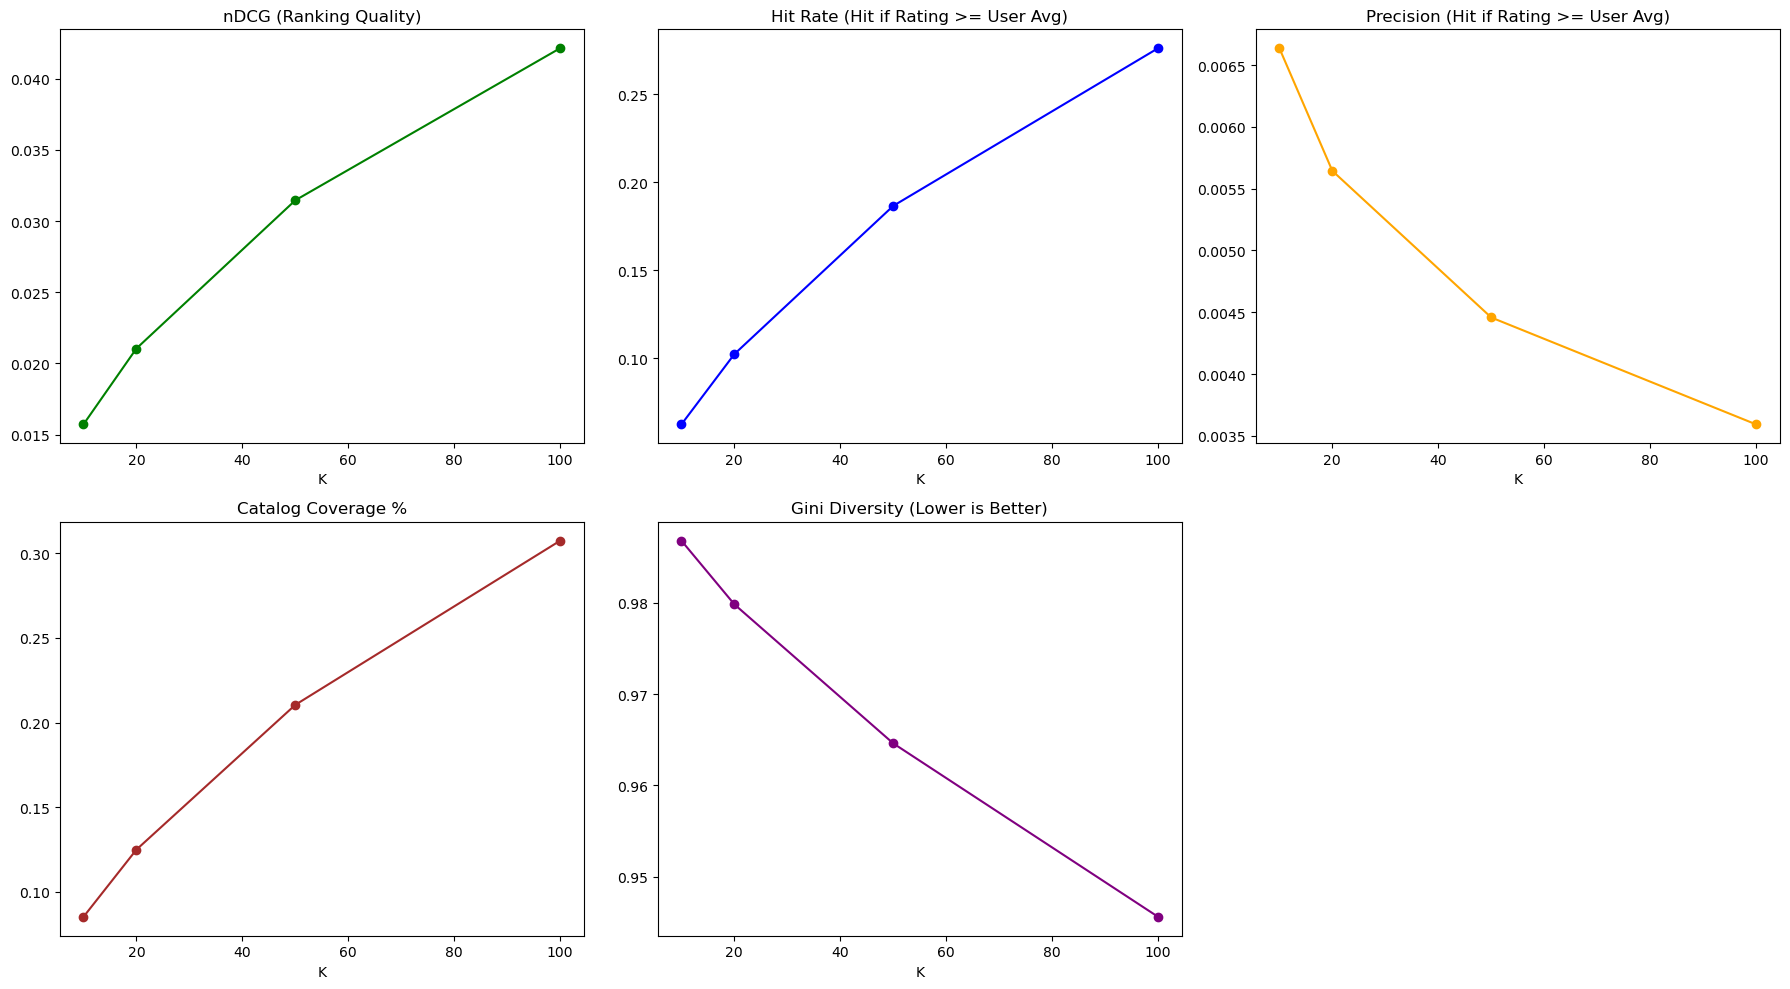

In [15]:
import pandas as pd
import numpy as np
import pickle
import time
import json
import warnings
import gc
from scipy.sparse import csr_matrix
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

# Suppress warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. LOAD MODEL
# ----------------------------------------------------------------------------
print("Loading model and artifacts...")
with open('lightfm_hybrid_model_75e_16d.pkl', 'rb') as f:
    checkpoint = pickle.load(f)

model = checkpoint['model']
item_id_map = checkpoint['item_id_map']
inv_item_id_map = checkpoint['inv_item_id_map'] 
user_features = checkpoint['user_features']
item_features = checkpoint['item_features']
train_interactions = checkpoint['train_interactions']
test_interactions = checkpoint['test_interactions']

# Convert to CSR and float32
train_csr = train_interactions.tocsr().astype(np.float32)
test_csr = test_interactions.tocsr().astype(np.float32)

# Filter: Only evaluate users who actually exist in the test set
test_user_indices = np.array([u for u in range(test_csr.shape[0]) if test_csr[u].getnnz() > 0])

print(f"Model loaded. Evaluating on {len(test_user_indices)} test users.")

# ----------------------------------------------------------------------------
# 2. PRE-COMPUTE EMBEDDINGS
# ----------------------------------------------------------------------------
print("Pre-computing representations...")
user_biases, user_embeddings = model.get_user_representations(features=user_features)
item_biases, item_embeddings = model.get_item_representations(features=item_features)

# Cast to float32
user_biases = user_biases.astype(np.float32)
user_embeddings = user_embeddings.astype(np.float32)
item_biases = item_biases.astype(np.float32)
item_embeddings = item_embeddings.astype(np.float32)

# Slice only test users
test_user_biases = user_biases[test_user_indices]
test_user_embeddings = user_embeddings[test_user_indices]

del user_features, item_features, checkpoint
gc.collect()

# ----------------------------------------------------------------------------
# 3. WORKER FUNCTION (PERSONALIZED THRESHOLDS)
# ----------------------------------------------------------------------------
def process_batch(batch_indices, 
                  batch_u_biases, batch_u_embs, 
                  all_i_biases, all_i_embs,
                  train_csr_sub, test_csr_sub, 
                  k_list,
                  debug_mode=False, inv_item_map=None):
    
    # --- 1. PREDICTION ---
    batch_scores = (batch_u_biases[:, None] + all_i_biases) + \
                   (batch_u_embs @ all_i_embs.T)

    # --- 2. MASK TRAINING ITEMS ---
    for row_i in range(len(batch_indices)):
        seen_indices = train_csr_sub[row_i].indices
        batch_scores[row_i, seen_indices] = -np.inf

    # --- 3. SORT TOP K ---
    max_k = max(k_list)
    top_k_unsorted_arg = np.argpartition(-batch_scores, max_k, axis=1)[:, :max_k]
    top_k_sorted = np.zeros(top_k_unsorted_arg.shape, dtype=int)
    
    for i in range(len(batch_indices)):
        indices = top_k_unsorted_arg[i]
        scores = batch_scores[i, indices]
        top_k_sorted[i] = indices[np.argsort(-scores)]

    # --- 4. CALCULATE METRICS ---
    batch_metrics = {
        'ndcg': {k: 0.0 for k in k_list},
        'hit_rate': {k: 0 for k in k_list},     
        'precision': {k: 0.0 for k in k_list},
        'rec_counts': {k: {} for k in k_list},
        'count': len(batch_indices)
    }

    for i in range(len(batch_indices)):
        # Get Test Items (Hidden Truth)
        true_indices = test_csr_sub[i].indices
        true_ratings = test_csr_sub[i].data
        true_map = dict(zip(true_indices, true_ratings))
        
        # --- PERSONALIZED THRESHOLD CALCULATION ---
        # 1. Get user's history from TRAIN data
        hist_ratings = train_csr_sub[i].data
        
        if len(hist_ratings) > 0:
            user_mean_rating = np.mean(hist_ratings)
        else:
            # Cold start fallback (if user has 0 train ratings but has test ratings)
            # Use 3.0 or the global mean
            user_mean_rating = 3.0
            
        # 2. Define "Positive" Test Items
        # A Hit is an item rated >= User's Average
        # If user is super critical (avg 1.5), then a 2.0 is a Hit.
        positive_mask = true_ratings >= user_mean_rating
        positive_items_set = set(true_indices[positive_mask])
        
        # Predictions
        recs = top_k_sorted[i]

        # --- DEBUG PRINT (First user only) ---
        if debug_mode and i == 0:
            print(f"\n--- DEBUG USER {batch_indices[0]} ---")
            print(f"User Train Mean Rating: {user_mean_rating:.2f}")
            print(f"Test Items (Total): {len(true_indices)}")
            print(f"Test Items (Positive >= {user_mean_rating:.2f}): {len(positive_items_set)}")
            print(f"Top 10 Recs: {[inv_item_map.get(x,x) for x in recs[:10]]}")
            
            # Check for ANY overlap
            hits = set(recs[:max_k]).intersection(positive_items_set)
            print(f"Hits found in Top {max_k}: {len(hits)}")
            print("------------------------------------\n")

        for k in k_list:
            top_k_recs = recs[:k]
            
            # --- Precision & Hit Rate (Personalized) ---
            hits = 0
            for item in top_k_recs:
                if item in positive_items_set:
                    hits += 1
            
            # Hit Rate: Did we find at least one "Good" item?
            if hits > 0:
                batch_metrics['hit_rate'][k] += 1
                
            # Precision: What % of recommendations were "Good"?
            batch_metrics['precision'][k] += (hits / k)

            # --- nDCG (Standard - using actual ratings) ---
            dcg = 0.0
            idcg = 0.0
            
            for rank, item in enumerate(top_k_recs):
                if item in true_map:
                    # Relevance = The actual rating
                    dcg += true_map[item] / np.log2(rank + 2)
            
            # IDCG: Ideal ordering of THIS user's test set
            sorted_true_vals = sorted(true_ratings, reverse=True)
            limit = min(len(sorted_true_vals), k)
            
            for rank in range(limit):
                idcg += sorted_true_vals[rank] / np.log2(rank + 2)
                
            if idcg > 0:
                batch_metrics['ndcg'][k] += (dcg / idcg)

            # --- Diversity ---
            for item in top_k_recs:
                batch_metrics['rec_counts'][k][item] = batch_metrics['rec_counts'][k].get(item, 0) + 1

    return batch_metrics

# ----------------------------------------------------------------------------
# 4. EXECUTE
# ----------------------------------------------------------------------------
k_values = [10, 20, 50, 100]
n_test_users = len(test_user_indices)
batch_size = 500
n_jobs = -1 

# Prepare batches
batches = []
for start in range(0, n_test_users, batch_size):
    end = min(start + batch_size, n_test_users)
    batch_idx_range = range(start, end)
    original_uids = test_user_indices[start:end]
    
    # Pre-slice to optimize speed
    train_sub = train_csr[original_uids]
    test_sub = test_csr[original_uids]
    
    batches.append((batch_idx_range, original_uids, train_sub, test_sub))

print(f"Starting evaluation on {n_test_users} users...")
start_time = time.time()

# 1. Run First Batch (Debug)
first_batch = batches[0]
print("Running debug batch...")
res_first = process_batch(
    first_batch[0],
    test_user_biases[first_batch[0]],
    test_user_embeddings[first_batch[0]],
    item_biases, item_embeddings,
    first_batch[2], first_batch[3],
    k_values,
    debug_mode=True, inv_item_map=inv_item_id_map
)

results = [res_first]

# 2. Run Remaining Batches (Parallel)
remaining_batches = batches[1:]
if remaining_batches:
    print(f"Running {len(remaining_batches)} batches in parallel...")
    res_rest = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(process_batch)(
            b_idx,
            test_user_biases[b_idx],
            test_user_embeddings[b_idx],
            item_biases, item_embeddings,
            train_sub, test_sub,
            k_values
        ) for b_idx, u_idx, train_sub, test_sub in remaining_batches
    )
    results.extend(res_rest)

print(f"Calculations completed in {time.time() - start_time:.2f}s")

# ----------------------------------------------------------------------------
# 5. AGGREGATE
# ----------------------------------------------------------------------------
print("Aggregating results...")

final_metrics = {
    'nDCG': {}, 'HitRate': {}, 'Precision': {}, 'Coverage': {}, 'Gini': {}
}

total_users = n_test_users
total_items = len(item_id_map)
global_counts = {k: {} for k in k_values}

for k in k_values:
    sum_ndcg = 0.0
    sum_hit = 0
    sum_precision = 0.0
    
    for res in results:
        sum_ndcg += res['ndcg'][k]
        sum_hit += res['hit_rate'][k]
        sum_precision += res['precision'][k]
        
        for item, cnt in res['rec_counts'][k].items():
            global_counts[k][item] = global_counts[k].get(item, 0) + cnt
            
    # Compute Averages
    final_metrics['nDCG'][k] = sum_ndcg / total_users
    final_metrics['HitRate'][k] = sum_hit / total_users
    final_metrics['Precision'][k] = sum_precision / total_users
    
    # Coverage
    unique_items = len(global_counts[k])
    final_metrics['Coverage'][k] = unique_items / total_items
    
    # Gini Coefficient
    counts_array = np.zeros(total_items, dtype=np.float32)
    if global_counts[k]:
        counts_array[np.array(list(global_counts[k].keys()))] = np.array(list(global_counts[k].values()))
        
    sorted_counts = np.sort(counts_array)
    n = total_items
    sum_vals = np.sum(sorted_counts)
    
    if sum_vals == 0:
        final_metrics['Gini'][k] = 0.0
    else:
        index = np.arange(1, n + 1)
        numerator = np.sum((2 * index - n - 1) * sorted_counts)
        denominator = n * sum_vals
        final_metrics['Gini'][k] = numerator / denominator

# ----------------------------------------------------------------------------
# 6. OUTPUT & SAVE
# ----------------------------------------------------------------------------
print("\n--- Final Personalized Evaluation Results ---")
print(json.dumps(final_metrics, indent=4))

with open('lightfm_hybrid_evaluation_results.json', 'w') as f:
    json.dump(final_metrics, f, indent=4)

# Plotting
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# 1. nDCG
axs[0, 0].plot(k_values, [final_metrics['nDCG'][k] for k in k_values], 'g-o')
axs[0, 0].set_title('nDCG (Ranking Quality)')
axs[0, 0].set_xlabel('K')

# 2. Hit Rate
axs[0, 1].plot(k_values, [final_metrics['HitRate'][k] for k in k_values], 'b-o')
axs[0, 1].set_title('Hit Rate (Hit if Rating >= User Avg)')
axs[0, 1].set_xlabel('K')

# 3. Precision
axs[0, 2].plot(k_values, [final_metrics['Precision'][k] for k in k_values], 'orange', marker='o')
axs[0, 2].set_title('Precision (Hit if Rating >= User Avg)')
axs[0, 2].set_xlabel('K')

# 4. Coverage
axs[1, 0].plot(k_values, [final_metrics['Coverage'][k] for k in k_values], 'brown', marker='o')
axs[1, 0].set_title('Catalog Coverage %')
axs[1, 0].set_xlabel('K')

# 5. Gini
axs[1, 1].plot(k_values, [final_metrics['Gini'][k] for k in k_values], 'purple', marker='o')
axs[1, 1].set_title('Gini Diversity (Lower is Better)')
axs[1, 1].set_xlabel('K')

axs[1, 2].axis('off')
plt.tight_layout()
plt.show()